# GSE252027 阶段 01：数据处理与差异分析

本笔记沿着 `experiments/01_preprocessing_differential/` 的代码走一遍阶段 01 的数据流：

**原始定量 → 长度缩放计数 → 文库大小因子 → 总体时间检验与逐时间点比较 → 功能与通路富集 → 图**

笔记只读取已经生成的输出，不重新拟合模型，几秒内即可跑完；显示的统计量、表格和图片与工程脚本一致。

**运行前提**：先按 [阶段 01 运行说明](../experiments/01_preprocessing_differential/README.md) 生成 `outputs/01_preprocessing_differential/`。

| 代码 | 负责什么 | 本笔记小节 |
|---|---|---|
| `prepare.py` | 读定量归档、过滤基因行、长度缩放计数、样本纳入表 | 1、2 |
| `differential.py` | 负二项模型、总体 LRT、五个 Wald 对比、D28 敏感性 | 3、4、5 |
| `enrichment.py` | GO / KEGG 过度富集、KEGG GSEA | 6 |
| `visualize.py` | 六张中文图 | 6 |
| `go_reference.py`、`kegg_reference.py` | 注释数据库与 KEGG 快照的来源与校验 | 6 |

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, display
from scipy.stats import hypergeom

pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# 从项目根目录或 notebooks/ 目录启动都能定位项目根，并找到阶段 01 输出。
cwd = Path.cwd()
ROOT = next((path for path in (cwd, *cwd.parents) if (path / 'datasets/GSE252027').is_dir()), None)
if ROOT is None:
    raise FileNotFoundError('请从项目根目录或 notebooks/ 目录启动 JupyterLab。')

OUT = ROOT / 'outputs/01_preprocessing_differential'

# 笔记依赖的输出清单：缺任何一项都提示先运行工程脚本，而不是给出难懂的报错。
required = [
    'matrices/FB_TPM.tsv.gz',
    'matrices/timecourse_length_scaled_counts.tsv.gz',
    'matrices/timecourse_normalized_counts.tsv.gz',
    'matrices/timecourse_vst.tsv.gz',
    'tables/sample_inclusion.csv',
    'tables/discovery_qc.csv',
    'tables/timecourse_size_factors.tsv',
    'tables/timecourse_lrt.tsv.gz',
    'tables/timecourse_wald.tsv.gz',
    'tables/enrichment_go_ora.tsv.gz',
    'tables/enrichment_kegg_ora.tsv.gz',
    'tables/enrichment_kegg_gsea.tsv.gz',
]
missing = [name for name in required if not (OUT / name).exists()]
if missing:
    raise FileNotFoundError('缺少阶段 01 输出，请先运行工程脚本：' + '、'.join(missing))


def read_out(relative, **kwargs):
    """读取阶段 01 输出中的 TSV，默认第一列是行索引。"""
    kwargs.setdefault('sep', '\t')
    kwargs.setdefault('index_col', 0)
    return pd.read_csv(OUT / relative, **kwargs)


print(f'项目根目录：{ROOT}')
print(f'阶段输出目录：{OUT}')

项目根目录：E:\project\mi-dna-choice
阶段输出目录：E:\project\mi-dna-choice\outputs\01_preprocessing_differential


## 1 样本与纳入规则

GSE252027 的成纤维细胞（FB）数据以 **GSM 文库**为统计单位，每个文库通常汇总三只小鼠。
D0 是未损伤对照，其余时间点为心梗后采样。共 24 个提交文库，每个时间点 4 个。

表 1 GSE252027 成纤维细胞各采样时间点的提交文库数。

In [2]:
samples = pd.read_csv(ROOT / 'datasets/GSE252027/metadata/samples_FB.csv').set_index('gsm')

table1 = samples.groupby('day').size().rename('提交文库数').rename_axis('时间点（天）').to_frame()
display(table1)

,提交文库数
时间点（天）,
0,4
1,4
3,4
7,4
14,4
28,4


纳入规则来自论文与作者脚本的对照（`prepare.write_inclusion`）：

- **D3 排除两份异常重复**：论文报告 D3 有两个 FB 文库异常，作者脚本保留 D3r1 与 D3r4，因此主分析排除 **D3r2、D3r3**。
- **D28r4 主分析保留**：公开材料对它的取舍不一致，主分析保留，另做排除后的敏感性分析。

因此，24 个提交文库中主分析纳入 **22** 个（D3 只剩 2 个），敏感性分析再排除 D28r4，纳入 **21** 个。

In [3]:
inclusion = pd.read_csv(OUT / 'tables/sample_inclusion.csv').set_index('GSM编号')

print('提交文库数：', len(inclusion))
print('主分析纳入文库数：', int(inclusion['主分析纳入'].eq('是').sum()))
print('敏感性分析纳入文库数：', int(inclusion['敏感性分析纳入'].eq('是').sum()))

# 只显示被排除或另有依据的文库，其余都是“纳入主分析及敏感性分析”。
excluded = inclusion.loc[inclusion['依据'].ne('纳入主分析及敏感性分析'),
                         ['时间点（天）', '组内重复编号', '主分析纳入', '敏感性分析纳入', '依据']]
display(excluded)

提交文库数： 24
主分析纳入文库数： 22
敏感性分析纳入文库数： 21


,时间点（天）,组内重复编号,主分析纳入,敏感性分析纳入,依据
GSM编号,,,,,
GSM7992335,3,2,否,否,论文报告 D3 排除两份 FB 文库，作者脚本保留 r1 和 r4
GSM7992336,3,3,否,否,论文报告 D3 排除两份 FB 文库，作者脚本保留 r1 和 r4
GSM7992349,28,4,是,否,论文未明确排除该 FB 文库，主分析保留并另做排除敏感性分析


`prepare.load_fb` 还会逐文库记录质控量。下面汇总每个文库的特征行数、基因行数、估计片段总量
和 TPM 达到 1 的基因数，用来核对定量文件是否来自同一套流程。

In [4]:
qc = pd.read_csv(OUT / 'tables/discovery_qc.csv')

columns = ['全部特征数', '基因行数', '排除的非基因行数', '全部估计片段数', 'TPM大于等于1的基因数']
qc_summary = qc[columns].agg(['min', 'median', 'max'])
display(qc_summary.map(lambda value: f'{value:,.0f}'))

print('全部特征数取值：', sorted(int(value) for value in qc['全部特征数'].unique()))
print('基因行数取值：', sorted(int(value) for value in qc['基因行数'].unique()))
print('排除的非基因行数取值：', sorted(int(value) for value in qc['排除的非基因行数'].unique()))

,全部特征数,基因行数,排除的非基因行数,全部估计片段数,TPM大于等于1的基因数
min,"51,398","51,029",369,"2,664,338","5,573"
median,"51,398","51,029",369,"26,614,078","11,436"
max,"51,398","51,029",369,"36,545,715","12,455"


全部特征数取值： [51398]
基因行数取值： [51029]
排除的非基因行数取值： [369]


## 2 从 TPM 到整数计数

差异模型需要“计数”而不是 TPM。`prepare.length_scaled_counts` 用与 tximport `lengthScaledTPM` 相同的公式，
按**本次纳入的文库**重建整数计数。设 $S$ 为纳入文库集合，$L_{ij}$ 为有效长度，$R_{ij}$ 为原始估计片段数：

$$
\overline L_i=\frac{1}{|S|}\sum_{j\in S}L_{ij},\qquad
U_{ij}=T_{ij}\,\overline L_i,\qquad
C_{ij}=\operatorname{round}\left(U_{ij}\cdot\frac{\sum_h R_{hj}}{\sum_h U_{hj}}\right).
$$

第一步给同一基因使用跨文库的平均有效长度，第二步按每列原始片段总量缩放，使每列总量守恒。

In [5]:
tpm = read_out('matrices/FB_TPM.tsv.gz')
effective_length = read_out('matrices/FB_EffectiveLength.tsv.gz')
estimated_reads = read_out('matrices/FB_NumReads.tsv.gz')

# 只保留主分析的 22 个文库；矩阵列顺序与纳入表一致。
main_samples = inclusion.index[inclusion['主分析纳入'].eq('是')]
tpm_main = tpm[main_samples]
effective_main = effective_length[main_samples]
reads_main = estimated_reads[main_samples]

print('提交矩阵：', tpm.shape)
print('主分析矩阵：', tpm_main.shape)

提交矩阵： (51029, 24)
主分析矩阵： (51029, 22)


In [6]:
gene_id = 'ENSMUSG00000054196'   # Cthrc1：心梗后成纤维细胞中变化明显的基因。
sample_id = 'GSM7992326'         # D0 的第一个文库。

# 逐项复算 Cthrc1 在该文库的计数，步骤与 prepare.length_scaled_counts 一致。
mean_effective = effective_main.mean(axis=1)
unscaled = tpm_main.mul(mean_effective, axis=0)
library_ratio = reads_main.sum(axis=0) / unscaled.sum(axis=0)

steps = pd.DataFrame({
    '数值': [tpm_main.loc[gene_id, sample_id],
             mean_effective[gene_id],
             tpm_main.loc[gene_id, sample_id] * mean_effective[gene_id],
             library_ratio[sample_id]],
    '含义': ['该文库的 TPM',
             '22 个文库中该基因的平均有效长度',
             'TPM × 平均有效长度 = 长度缩放后的丰度',
             '该文库估计片段总量 ÷ 丰度列和'],
}, index=['TPM', '平均有效长度', '未缩放计数', '文库缩放比'])

display(steps.round(6))

manual = steps.loc['未缩放计数', '数值'] * steps.loc['文库缩放比', '数值']
saved_counts = read_out('matrices/timecourse_length_scaled_counts.tsv.gz')

print(f'手算值 {manual:.4f}，取整后 {manual:.0f}；保存矩阵中的值 {saved_counts.loc[gene_id, sample_id]}')
print('全矩阵重建结果与保存矩阵一致：', unscaled.mul(library_ratio, axis=1).round().astype('int64')
      .loc[saved_counts.index].equals(saved_counts))

,数值,含义
TPM,0.651286,该文库的 TPM
平均有效长度,472.378273,22 个文库中该基因的平均有效长度
未缩放计数,307.653356,TPM × 平均有效长度 = 长度缩放后的丰度
文库缩放比,0.082725,该文库估计片段总量 ÷ 丰度列和


手算值 25.4506，取整后 25；保存矩阵中的值 25
全矩阵重建结果与保存矩阵一致： True


低表达过滤规则：**至少存在一个时间组，该基因在组内 2 个文库的计数达到 10**。
这样只在单个时间窗口表达的基因也能进入模型。`differential.fit_time_model` 用这条规则把 51,029 个基因缩小到 19,312 个。

In [7]:
# 在全部基因上重建计数，再应用与工程脚本相同的过滤规则。
counts_all = unscaled.mul(library_ratio, axis=1).round().astype('int64')
days = samples.loc[main_samples, 'day']

expressed = pd.concat([
    (counts_all.loc[:, days.eq(day).to_numpy()] >= 10).sum(axis=1) >= 2
    for day in sorted(days.unique())
], axis=1).any(axis=1)

print(f'全部基因数：{len(counts_all):,}')
print(f'通过低表达过滤的基因数：{int(expressed.sum()):,}')
print('与保存矩阵的基因数一致：', int(expressed.sum()) == len(saved_counts))

全部基因数：51,029
通过低表达过滤的基因数：19,312
与保存矩阵的基因数一致： True


In [8]:
# 文库大小因子由中位数比值法估计，用于去掉文库间总体测序深度的差异。
size_factors = pd.read_csv(OUT / 'tables/timecourse_size_factors.tsv', sep='\t').set_index('GSM编号')
normalized = read_out('matrices/timecourse_normalized_counts.tsv.gz')
vst = read_out('matrices/timecourse_vst.tsv.gz')

frame = pd.DataFrame({
    '时间组': [f'D{day}' for day in days],
    '组内重复': samples.loc[main_samples, 'replicate'].to_numpy(),
    '长度缩放计数': saved_counts.loc[gene_id],
    '文库大小因子': size_factors['文库大小因子'],
    '归一化计数': normalized.loc[gene_id],
    'VST': vst.loc[gene_id],
}, index=main_samples)

display(frame.head(8).round(3))

# 归一化计数应等于计数除以大小因子。
difference = (normalized.loc[gene_id] - saved_counts.loc[gene_id] / size_factors['文库大小因子']).abs().max()
print(f'归一化计数与 计数 ÷ 大小因子 的最大差异：{difference:.2e}')

,时间组,组内重复,长度缩放计数,文库大小因子,归一化计数,VST
GSM编号,,,,,,
GSM7992326,D0,1,25,0.999,25.016,6.536
GSM7992327,D0,2,35,1.245,28.118,6.597
GSM7992328,D0,3,28,1.205,23.238,6.500
GSM7992329,D0,4,31,1.385,22.382,6.481
GSM7992330,D1,1,638,1.023,623.958,9.473
GSM7992331,D1,2,586,0.946,619.472,9.463
GSM7992332,D1,3,668,0.998,669.313,9.562
GSM7992333,D1,4,815,0.990,822.950,9.830


归一化计数与 计数 ÷ 大小因子 的最大差异：0.00e+00


In [9]:
# 描述性对照：Cthrc1 在全部 24 个提交文库中的平均 TPM（不参与模型拟合）。
gene_tpm = samples[['day']].assign(TPM=tpm.loc[gene_id])
display(gene_tpm.groupby('day')['TPM']
        .agg(提交文库数='size', 平均TPM='mean')
        .rename_axis('时间点（天）')
        .round(3))

,提交文库数,平均TPM
时间点（天）,,
0,4,0.556
1,4,13.661
3,4,73.532
7,4,98.724
14,4,36.802
28,4,5.117


## 3 总体时间效应：似然比检验

`differential.overall_lrt` 对每个基因比较两个嵌套模型：

- **简化模型**：六个时间组共用一个表达均值；
- **完整模型**：每个时间组各有均值。

两者固定同一份离散度与文库大小因子，统计量为 $D=2(\ell_{\text{完整}}-\ell_{\text{简化}})$，
在零假设“六组均值相等”下服从 $\chi^2_5$。Cook 距离标记的基因不参与 BH 校正，校正后 P 值留空。

In [10]:
lrt = read_out('tables/timecourse_lrt.tsv.gz')

print(f'进入模型的基因数：{len(lrt):,}')
print(f'总体时间效应显著的基因数：{int(lrt["总体时间效应显著"].eq("是").sum()):,}')

# 按校正后 P 值排序，最显著的基因在最上面。
display(lrt.head(6)[['基因符号', '平均标准化计数', 'LRT统计量', '校正后P值', '总体时间效应显著']]
        .round({'平均标准化计数': 1, 'LRT统计量': 2, '校正后P值': 12}))

display(lrt.loc[[gene_id], ['基因符号', 'LRT统计量', 'P值', '校正后P值', '总体时间效应显著']])

进入模型的基因数：19,312


总体时间效应显著的基因数：11,480


,基因符号,平均标准化计数,LRT统计量,校正后P值,总体时间效应显著
基因ID,,,,,
ENSMUSG00000006014,Prg4,8226.7,795.39,0.0,是
ENSMUSG00000054196,Cthrc1,2386.6,657.96,0.0,是
ENSMUSG00000028364,Tnc,9282.3,576.17,0.0,是
ENSMUSG00000031167,Rbm3,5538.3,498.62,0.0,是
ENSMUSG00000058914,C1qtnf3,617.6,490.42,0.0,是
ENSMUSG00000007739,Cct4,2867.2,477.58,0.0,是


,基因符号,LRT统计量,P值,校正后P值,总体时间效应显著
基因ID,,,,,
ENSMUSG00000054196,Cthrc1,657.959407,6.025960e-140,5.769857e-136,是


总体 LRT 回答“六个组之间是否存在任何差异”，但不告诉你哪一天变化、朝哪个方向。
后者由 `differential.wald_contrast` 对同一个六组模型做 Wald 对比得到：D1、D3、D7、D14、D28 分别对 D0。

In [11]:
wald = pd.read_csv(OUT / 'tables/timecourse_wald.tsv.gz', sep='\t')
contrast_summary = pd.read_csv(OUT / 'tables/timecourse_contrast_summary.tsv', sep='\t')

display(contrast_summary)

# Cthrc1 在五个时间对比中的效应与证据。
cthrc1 = wald[wald['基因ID'].eq(gene_id)].set_index('比较')[
    ['log2表达倍数变化', '效应标准误', '校正后P值', '通过差异筛选']]
display(cthrc1.round({'log2表达倍数变化': 2, '效应标准误': 3, '校正后P值': 12}))

print('五个比较的差异基因数合计（同一基因可在多个比较入选）：',
      int(wald['通过差异筛选'].eq('是').sum()))

,比较,文库数,有限校正P值基因数,上调基因数,下调基因数
0,D1_vs_D0,4,18775,849,431
1,D3_vs_D0,2,19150,2126,1259
2,D7_vs_D0,4,19150,1348,315
3,D14_vs_D0,4,19150,1163,133
4,D28_vs_D0,4,18775,760,106


,log2表达倍数变化,效应标准误,校正后P值,通过差异筛选
比较,,,,
D1_vs_D0,4.79,0.306,0.0,是
D3_vs_D0,8.27,0.362,0.0,是
D7_vs_D0,7.83,0.305,0.0,是
D14_vs_D0,6.74,0.305,0.0,是
D28_vs_D0,3.88,0.307,0.0,是


五个比较的差异基因数合计（同一基因可在多个比较入选）： 8490


## 4 D28r4 敏感性分析

用排除 D28r4 的 21 个文库重跑同一套模型，再比较两份显著名单的重合程度：

$$
J(A,B)=\frac{|A\cap B|}{|A\cup B|}.
$$

$J$ 越接近 1，说明结论对这一个样本的取舍越不敏感。逐基因的对照保存在
`tables/timecourse_d28_sensitivity.tsv.gz`。

In [12]:
sensitivity = pd.read_csv(OUT / 'tables/timecourse_sensitivity_summary.tsv', sep='\t')
display(sensitivity.round({'Jaccard指数': 4}))

# 用汇总表的计数复算 Jaccard，核对字段之间的算术关系。
row = sensitivity.iloc[0]
recomputed = row['共同入选基因数'] / (row['主分析入选基因数'] + row['敏感性分析入选基因数'] - row['共同入选基因数'])
print(f'按交集/并集复算 Jaccard：{recomputed:.4f}')

d28 = read_out('tables/timecourse_d28_sensitivity.tsv.gz')
display(d28.loc[[gene_id]].round(4))

,检验,主分析入选基因数,敏感性分析入选基因数,共同入选基因数,Jaccard指数
0,总体时间效应,11480,11602,10729,0.8685
1,D28_vs_D0,866,609,524,0.5510


按交集/并集复算 Jaccard：0.8685


,主分析总体校正后P值,敏感性总体校正后P值,主分析D28效应,敏感性D28效应,主分析D28校正后P值,敏感性D28校正后P值
基因ID,,,,,,
ENSMUSG00000054196,0.0,0.0,3.8794,3.8954,0.0,0.0


## 5 GO、KEGG 富集与 GSEA

两种富集从不同的基因名单出发：

- **过度富集（ORA）**：先用 `|log2FC| ≥ 1 且 padj < 0.05` 筛出差异基因，
  再用超几何检验比较条目的命中比例与背景。代码在 `enrichment.overrepresentation`。
- **GSEA**：不预先筛基因，把所有有有效 Wald 统计量的基因按**带符号**的统计量排序，
  看通路成员是否集中在某一端。代码在 `enrichment.prerank`。

`enrichment_summary.tsv` 汇总每个比较在各分析下的显著条目数。

In [13]:
enrichment_summary = pd.read_csv(OUT / 'tables/enrichment_summary.tsv', sep='\t')
order = [f'D{day}_vs_D0' for day in (1, 3, 7, 14, 28)]

display(enrichment_summary.pivot(index='分析', columns='比较', values='显著条目数').reindex(columns=order))

比较,D1_vs_D0,D3_vs_D0,D7_vs_D0,D14_vs_D0,D28_vs_D0
分析,,,,,
GO_ORA,342,406,871,419,149
KEGG_GSEA,165,155,73,62,96
KEGG_ORA,21,22,45,19,20


In [14]:
go = pd.read_csv(OUT / 'tables/enrichment_go_ora.tsv.gz', sep='\t')

# D7 上调基因的 GO 生物过程结果，按校正后 P 值取前 5 项。
go_d7_up = go[(go['比较'].eq('D7_vs_D0')) & (go['方向'].eq('上调')) & (go['注释集'].eq('BP'))]
go_columns = ['条目ID', '条目原名', '命中数', '候选数', '背景条目大小', '背景基因数', '富集倍数', '校正后P值']
display(go_d7_up.nsmallest(5, '校正后P值')[go_columns]
        .round({'富集倍数': 2, '校正后P值': 12}))

,条目ID,条目原名,命中数,候选数,背景条目大小,背景基因数,富集倍数,校正后P值
62609,GO:0001501,skeletal system development,87,1169,492,14884,2.25,3.050000e-10
62610,GO:0007094,mitotic spindle assembly checkpoint signaling,22,1169,44,14884,6.37,3.050000e-10
62611,GO:0031577,spindle checkpoint signaling,22,1169,45,14884,6.22,3.050000e-10
62612,GO:0033046,negative regulation of sister chromatid segreg...,22,1169,46,14884,6.09,3.050000e-10
62613,GO:0033048,negative regulation of mitotic sister chromati...,22,1169,46,14884,6.09,3.050000e-10


In [15]:
# 用第一行参数手算超几何右尾概率，核对表中的 P 值。
row = go_d7_up.nsmallest(1, '校正后P值').iloc[0]
recomputed = hypergeom.sf(row['命中数'] - 1, row['背景基因数'], row['背景条目大小'], row['候选数'])

print(row['条目ID'], row['条目原名'])
print(f'N={row["背景基因数"]:,}，K={row["背景条目大小"]:,}，n={row["候选数"]:,}，k={row["命中数"]}')
print(f'手算 P 值 {recomputed:.3e}，表中 P 值 {row["P值"]:.3e}')

GO:0001501 skeletal system development
N=14,884，K=492，n=1,169，k=87
手算 P 值 3.730e-13，表中 P 值 3.730e-13


In [16]:
kegg = pd.read_csv(OUT / 'tables/enrichment_kegg_ora.tsv.gz', sep='\t')

kegg_d7_up = kegg[(kegg['比较'].eq('D7_vs_D0')) & (kegg['方向'].eq('上调'))]
kegg_columns = ['条目ID', '条目原名', '命中数', '候选数', '背景条目大小', '背景基因数', '富集倍数', '校正后P值']

display(kegg_d7_up.nsmallest(5, '校正后P值')[kegg_columns]
        .round({'富集倍数': 2, '校正后P值': 12}))

,条目ID,条目原名,命中数,候选数,背景条目大小,背景基因数,富集倍数,校正后P值
2794,mmu04512,ECM-receptor interaction,26,600,82,6881,3.64,8.961350e-07
2795,mmu05322,Systemic lupus erythematosus,27,600,91,6881,3.40,1.129953e-06
2798,mmu04060,Cytokine-cytokine receptor interaction,40,600,184,6881,2.49,4.113969e-06
2801,mmu04514,Cell adhesion molecule (CAM) interaction,28,600,119,6881,2.70,4.648649e-05
2802,mmu04974,Protein digestion and absorption,21,600,74,6881,3.25,4.648649e-05


GSEA 的 NES 带方向：**正值**表示通路成员偏向上调端，**负值**表示偏向下调端。
`核心基因EntrezID` 是推动富集峰的那部分成员，可以回到 `enrichment_gene_mapping.tsv` 查基因符号。

In [17]:
gsea = pd.read_csv(OUT / 'tables/enrichment_kegg_gsea.tsv.gz', sep='\t')
gsea_d7 = gsea[gsea['比较'].eq('D7_vs_D0')]
significant = gsea_d7[gsea_d7['校正后P值'].lt(0.05)]

# 正、负方向各取 4 条，便于比较两类信号。
top_positive = significant.nlargest(4, '标准化富集分数NES')
top_negative = significant.nsmallest(4, '标准化富集分数NES')
gsea_columns = ['条目ID', '条目原名', '集合大小', '富集分数ES', '标准化富集分数NES', 'P值', '校正后P值']

display(pd.concat([top_positive, top_negative])[gsea_columns]
        .round({'富集分数ES': 3, '标准化富集分数NES': 2, 'P值': 10, '校正后P值': 10}))

print(f'D7 显著通路数：{len(significant)}'
      f'（NES > 0：{int(significant["标准化富集分数NES"].gt(0).sum())}，'
      f'NES < 0：{int(significant["标准化富集分数NES"].lt(0).sum())}）')

,条目ID,条目原名,集合大小,富集分数ES,标准化富集分数NES,P值,校正后P值
1360,mmu05150,Staphylococcus aureus infection,41,0.694,2.11,8.507000e-07,1.681340e-05
1358,mmu04974,Protein digestion and absorption,74,0.609,2.04,6.616000e-07,1.415910e-05
1359,mmu05322,Systemic lupus erythematosus,91,0.580,1.99,6.742000e-07,1.415910e-05
1361,mmu04512,ECM-receptor interaction,82,0.583,1.98,9.011000e-07,1.682030e-05
1344,mmu00190,Oxidative phosphorylation,122,-0.565,-2.52,0.000000e+00,1.000000e-10
1350,mmu04932,Non-alcoholic fatty liver disease,145,-0.474,-2.18,1.000000e-10,4.500000e-09
1346,mmu05208,Chemical carcinogenesis - reactive oxygen species,209,-0.441,-2.14,0.000000e+00,1.000000e-10
1347,mmu04714,Thermogenesis,218,-0.426,-2.10,0.000000e+00,7.000000e-10


D7 显著通路数：73（NES > 0：37，NES < 0：36）


## 6 六张图怎么读

`visualize.py` 只读取上面这些矩阵和表格，不重新拟合模型。

- **图 1、图 3 的样本范围不同**：图 1 用全部 24 个提交文库做 log2(TPM+1) PCA，用来定位待核对的样本；
  图 3 用 22 个主分析文库的 VST 做 PCA。两张图的点不能逐个对应。
- **图 2** 的上下两栏使用相同基因、相同文库，比较标准化前后的分布，箱体颜色表示时间组。
- **图 4** 对每个基因做行内标准化，颜色只表示**同一基因**在不同文库中的相对高低。
- **图 5** 横轴是 log2FC，纵轴是 $-\log_{10}(\text{padj})$，虚线为 $|log2FC|=1$ 与 padj = 0.05。
- **图 6** 用 D7 做代表：GO 生物过程与 KEGG 上调 ORA 各取前 5，GSEA 正负方向各取前 3。

图 1  成纤维细胞提交文库的主成分分析


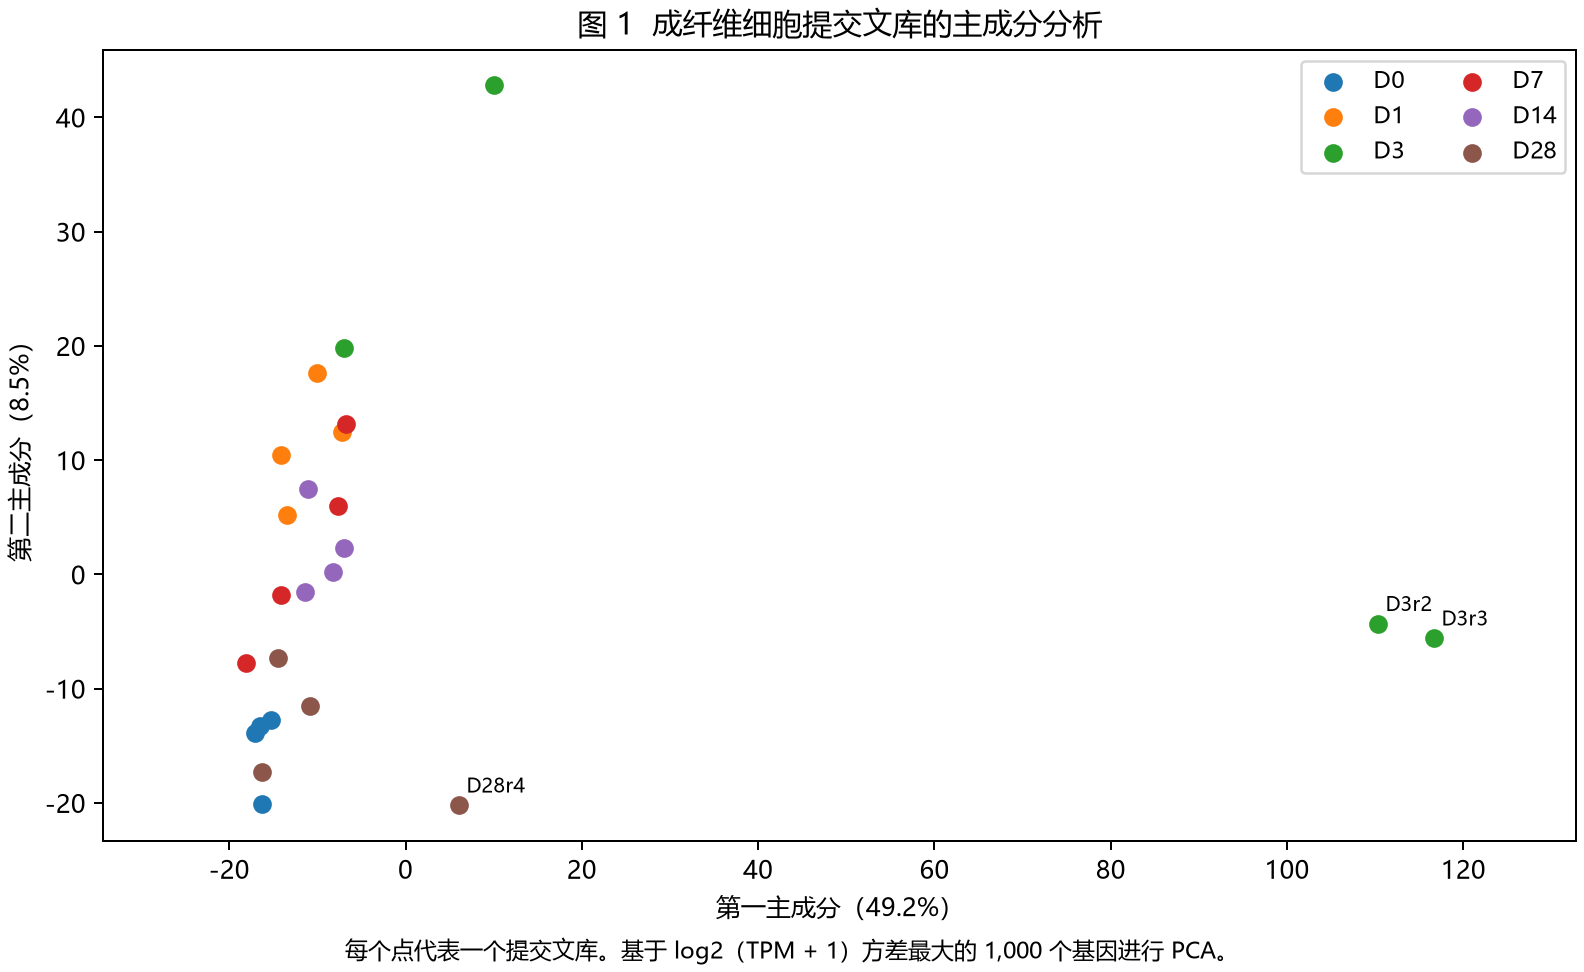

图 2  主分析文库标准化前后的计数分布


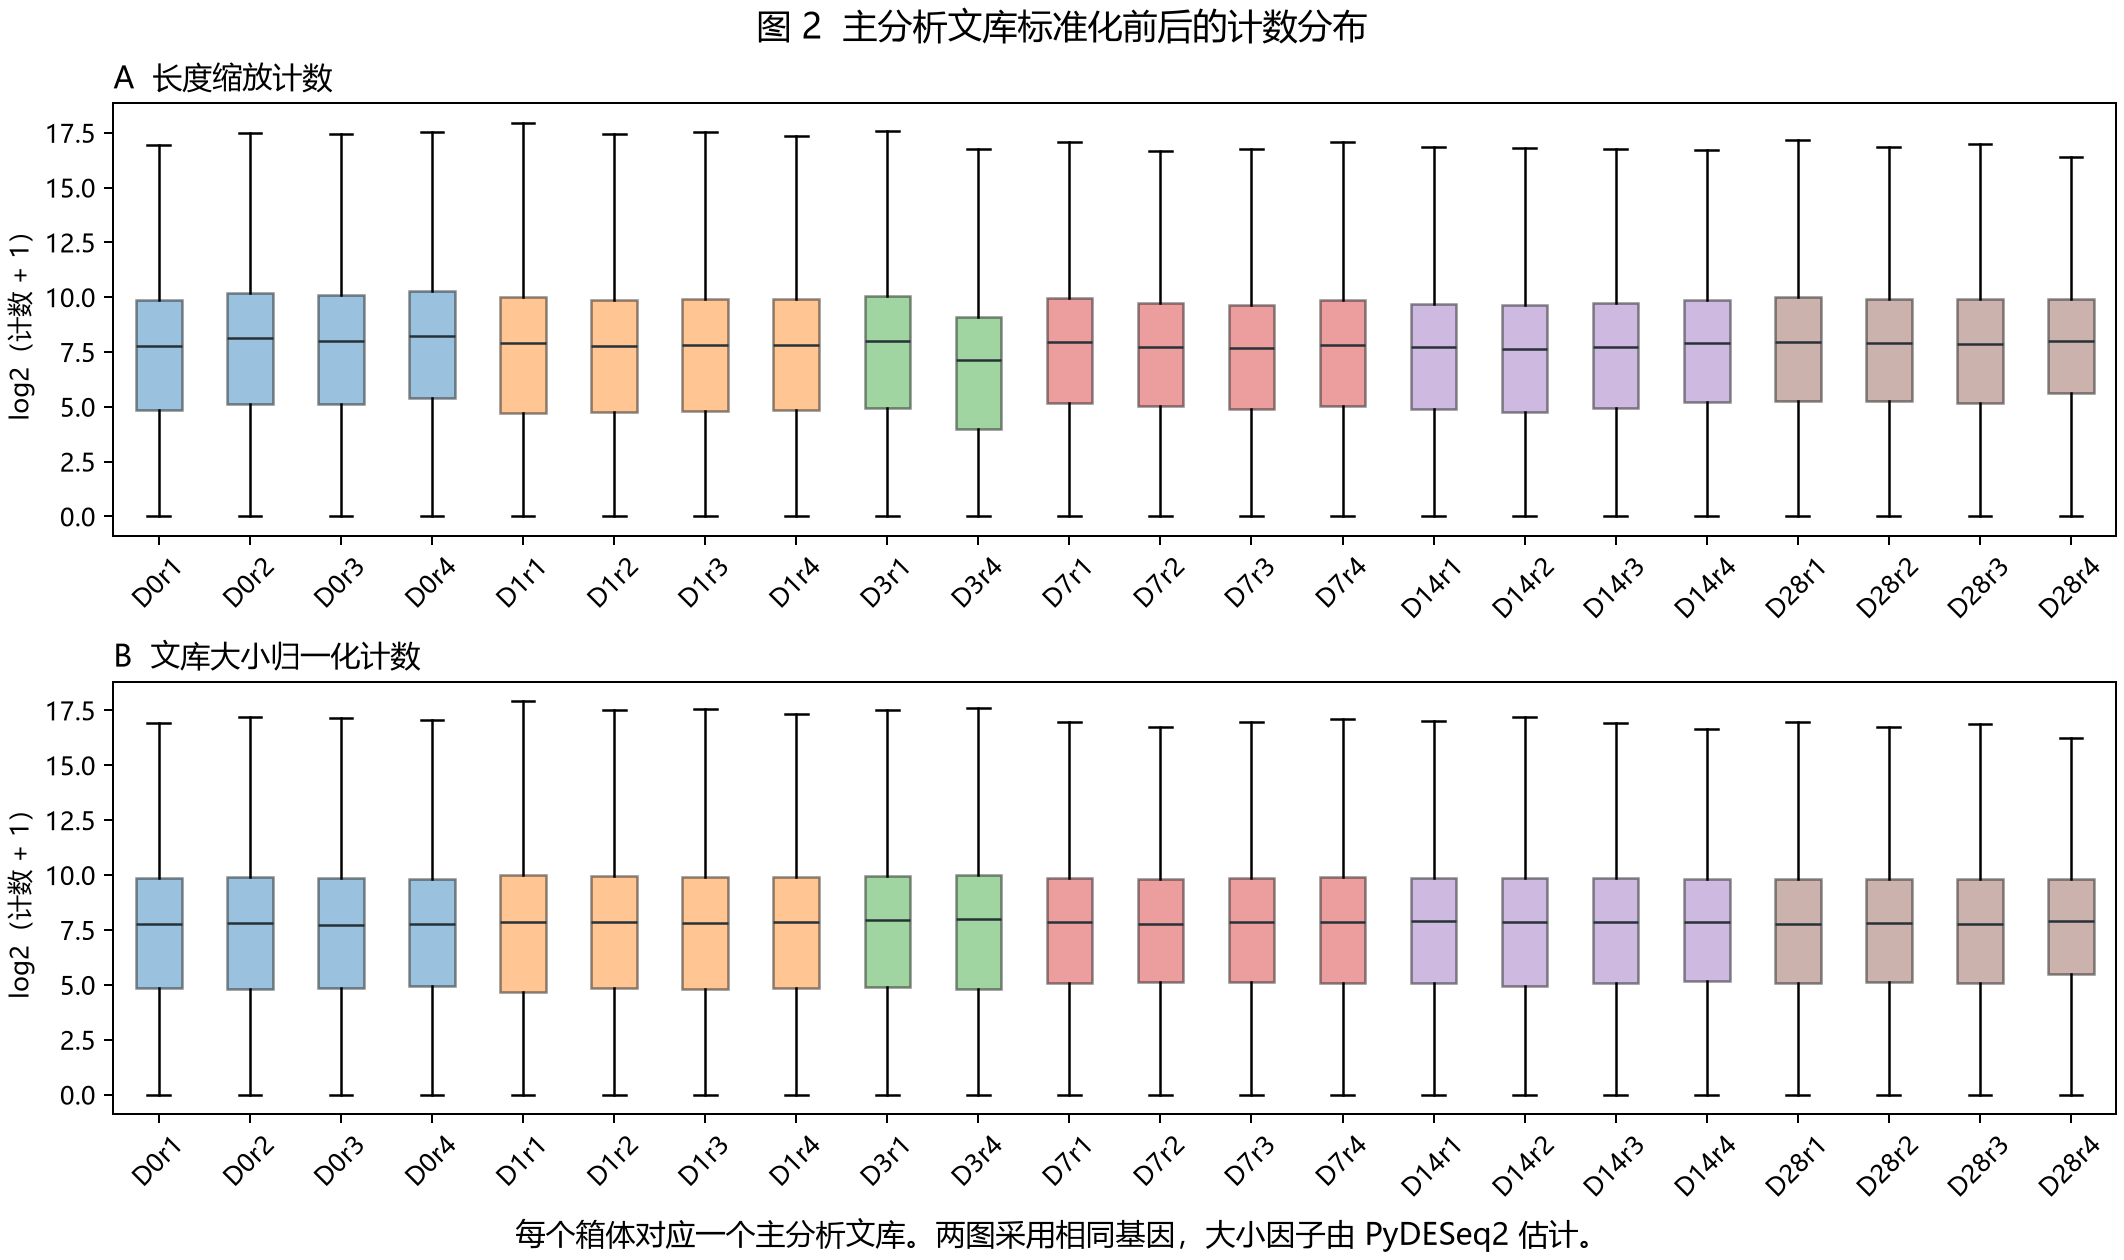

图 3  标准化后成纤维细胞文库的主成分分析


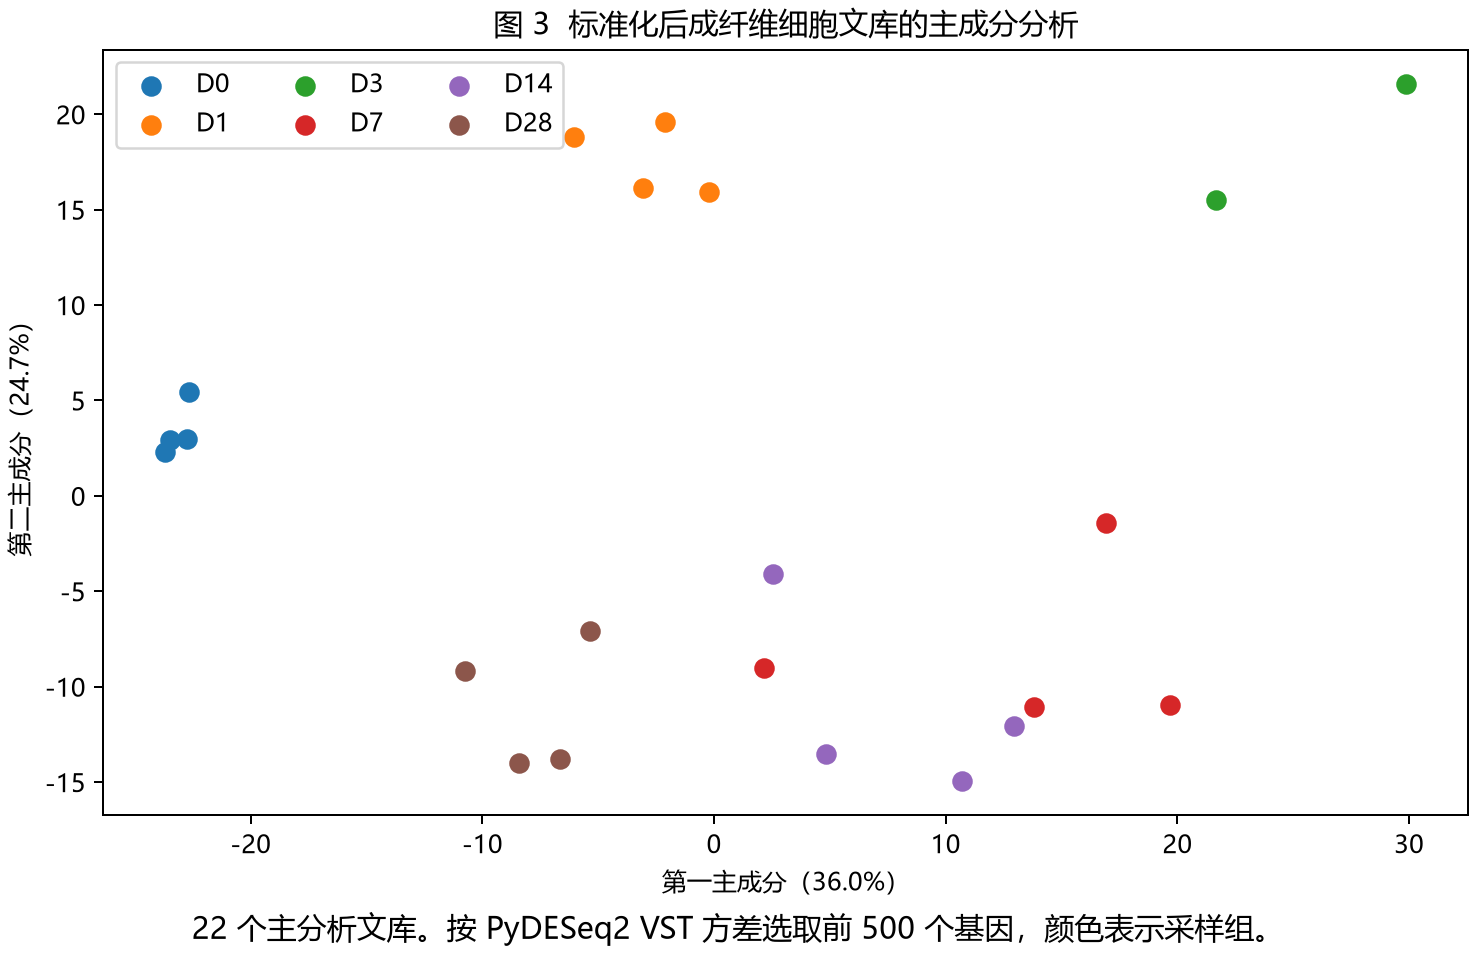

In [18]:
figures = [
    ('01_submitted_library_pca.png', '图 1  成纤维细胞提交文库的主成分分析'),
    ('02_timecourse_normalization.png', '图 2  主分析文库标准化前后的计数分布'),
    ('03_timecourse_pca.png', '图 3  标准化后成纤维细胞文库的主成分分析'),
]

for name, caption in figures:
    print(caption)
    display(Image(filename=str(OUT / 'figures' / name), width=860))

图 4  总体时间效应排名前 25 个基因的表达模式


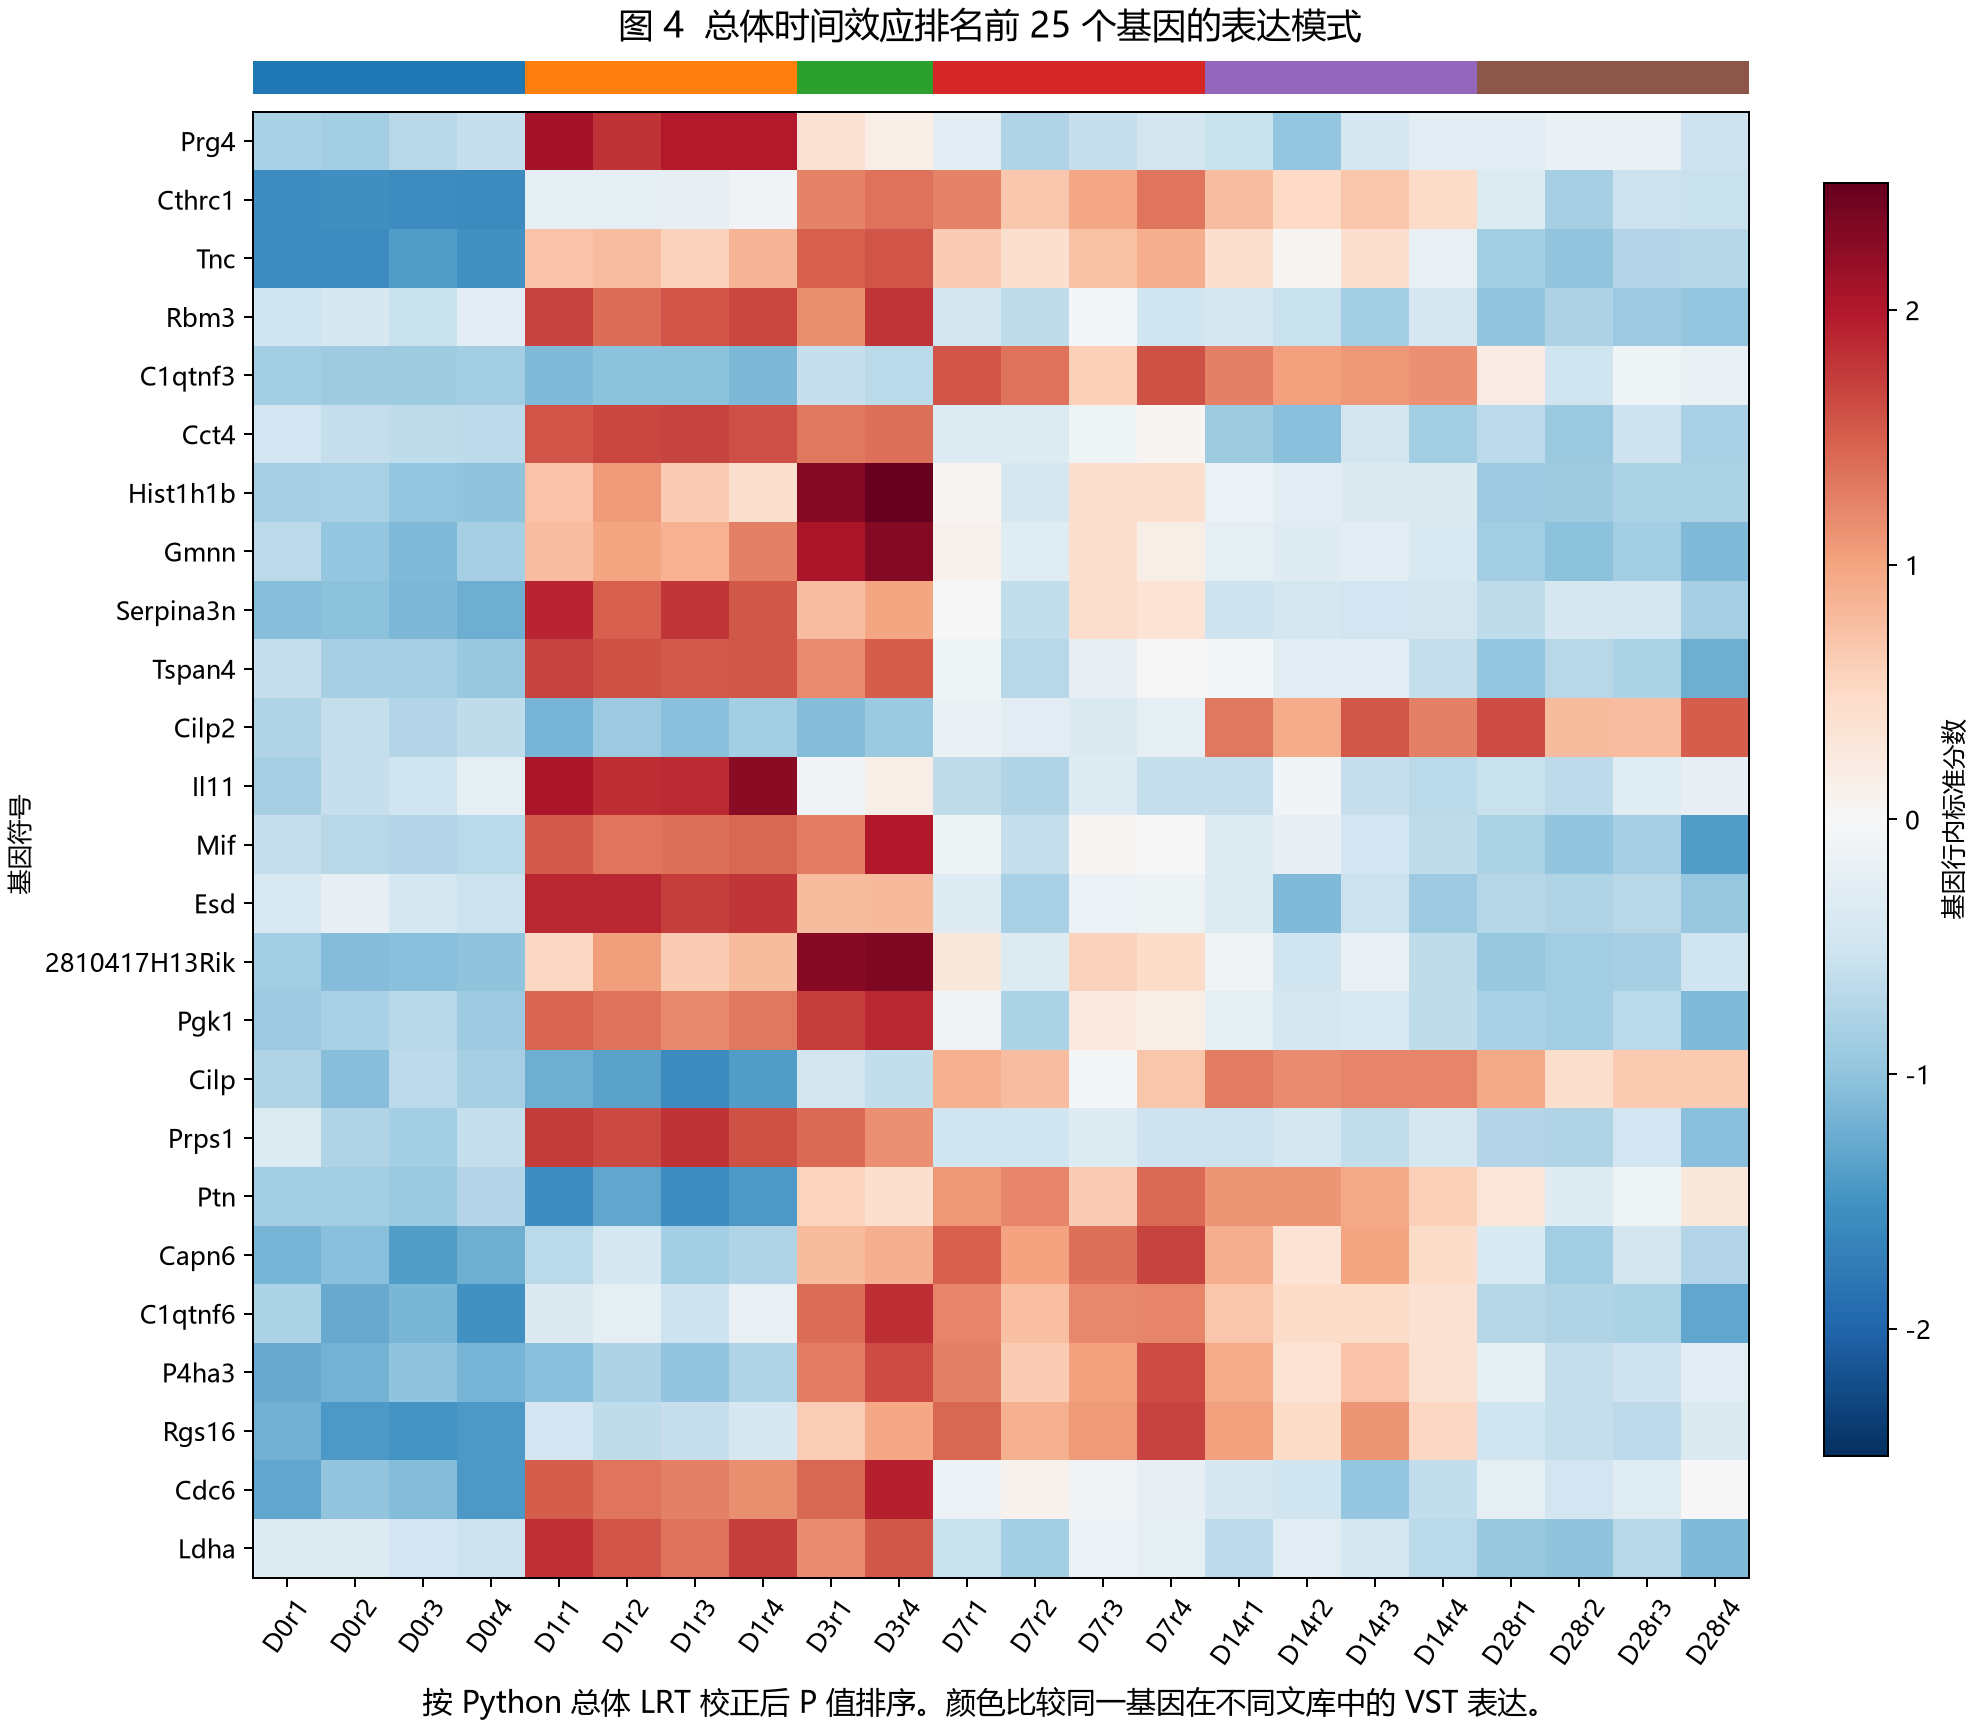

图 5  心梗后各时间点相对未损伤对照的差异表达


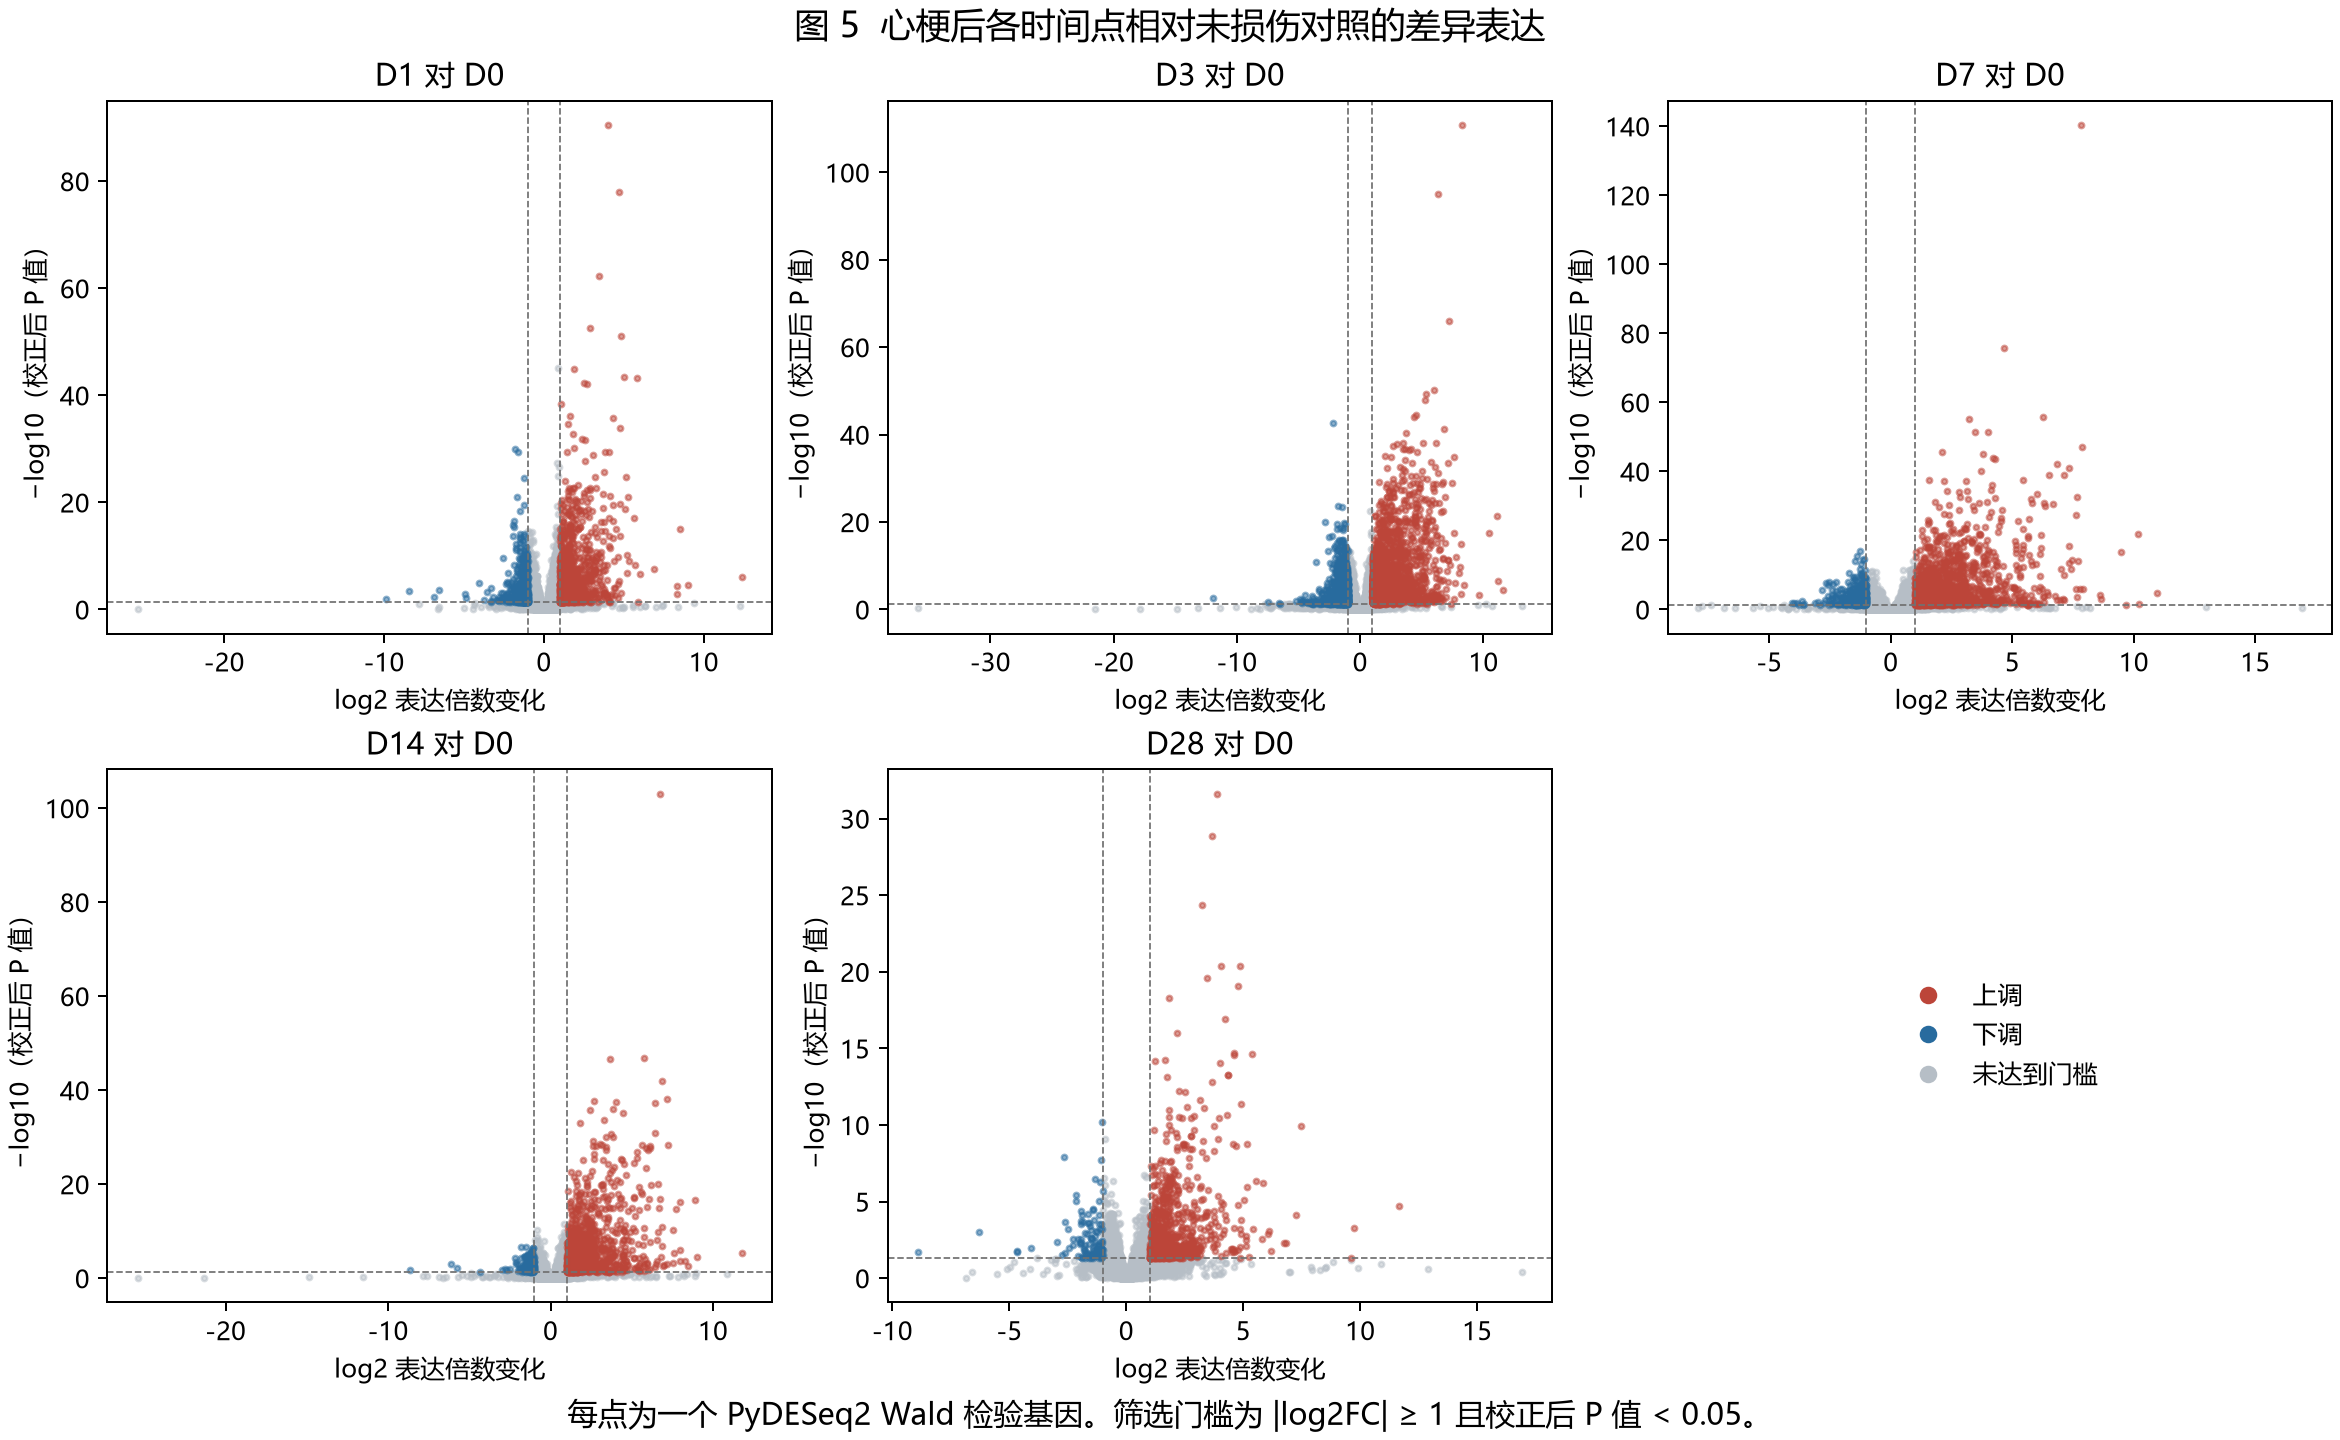

图 6  心梗后第 7 天的功能与通路富集


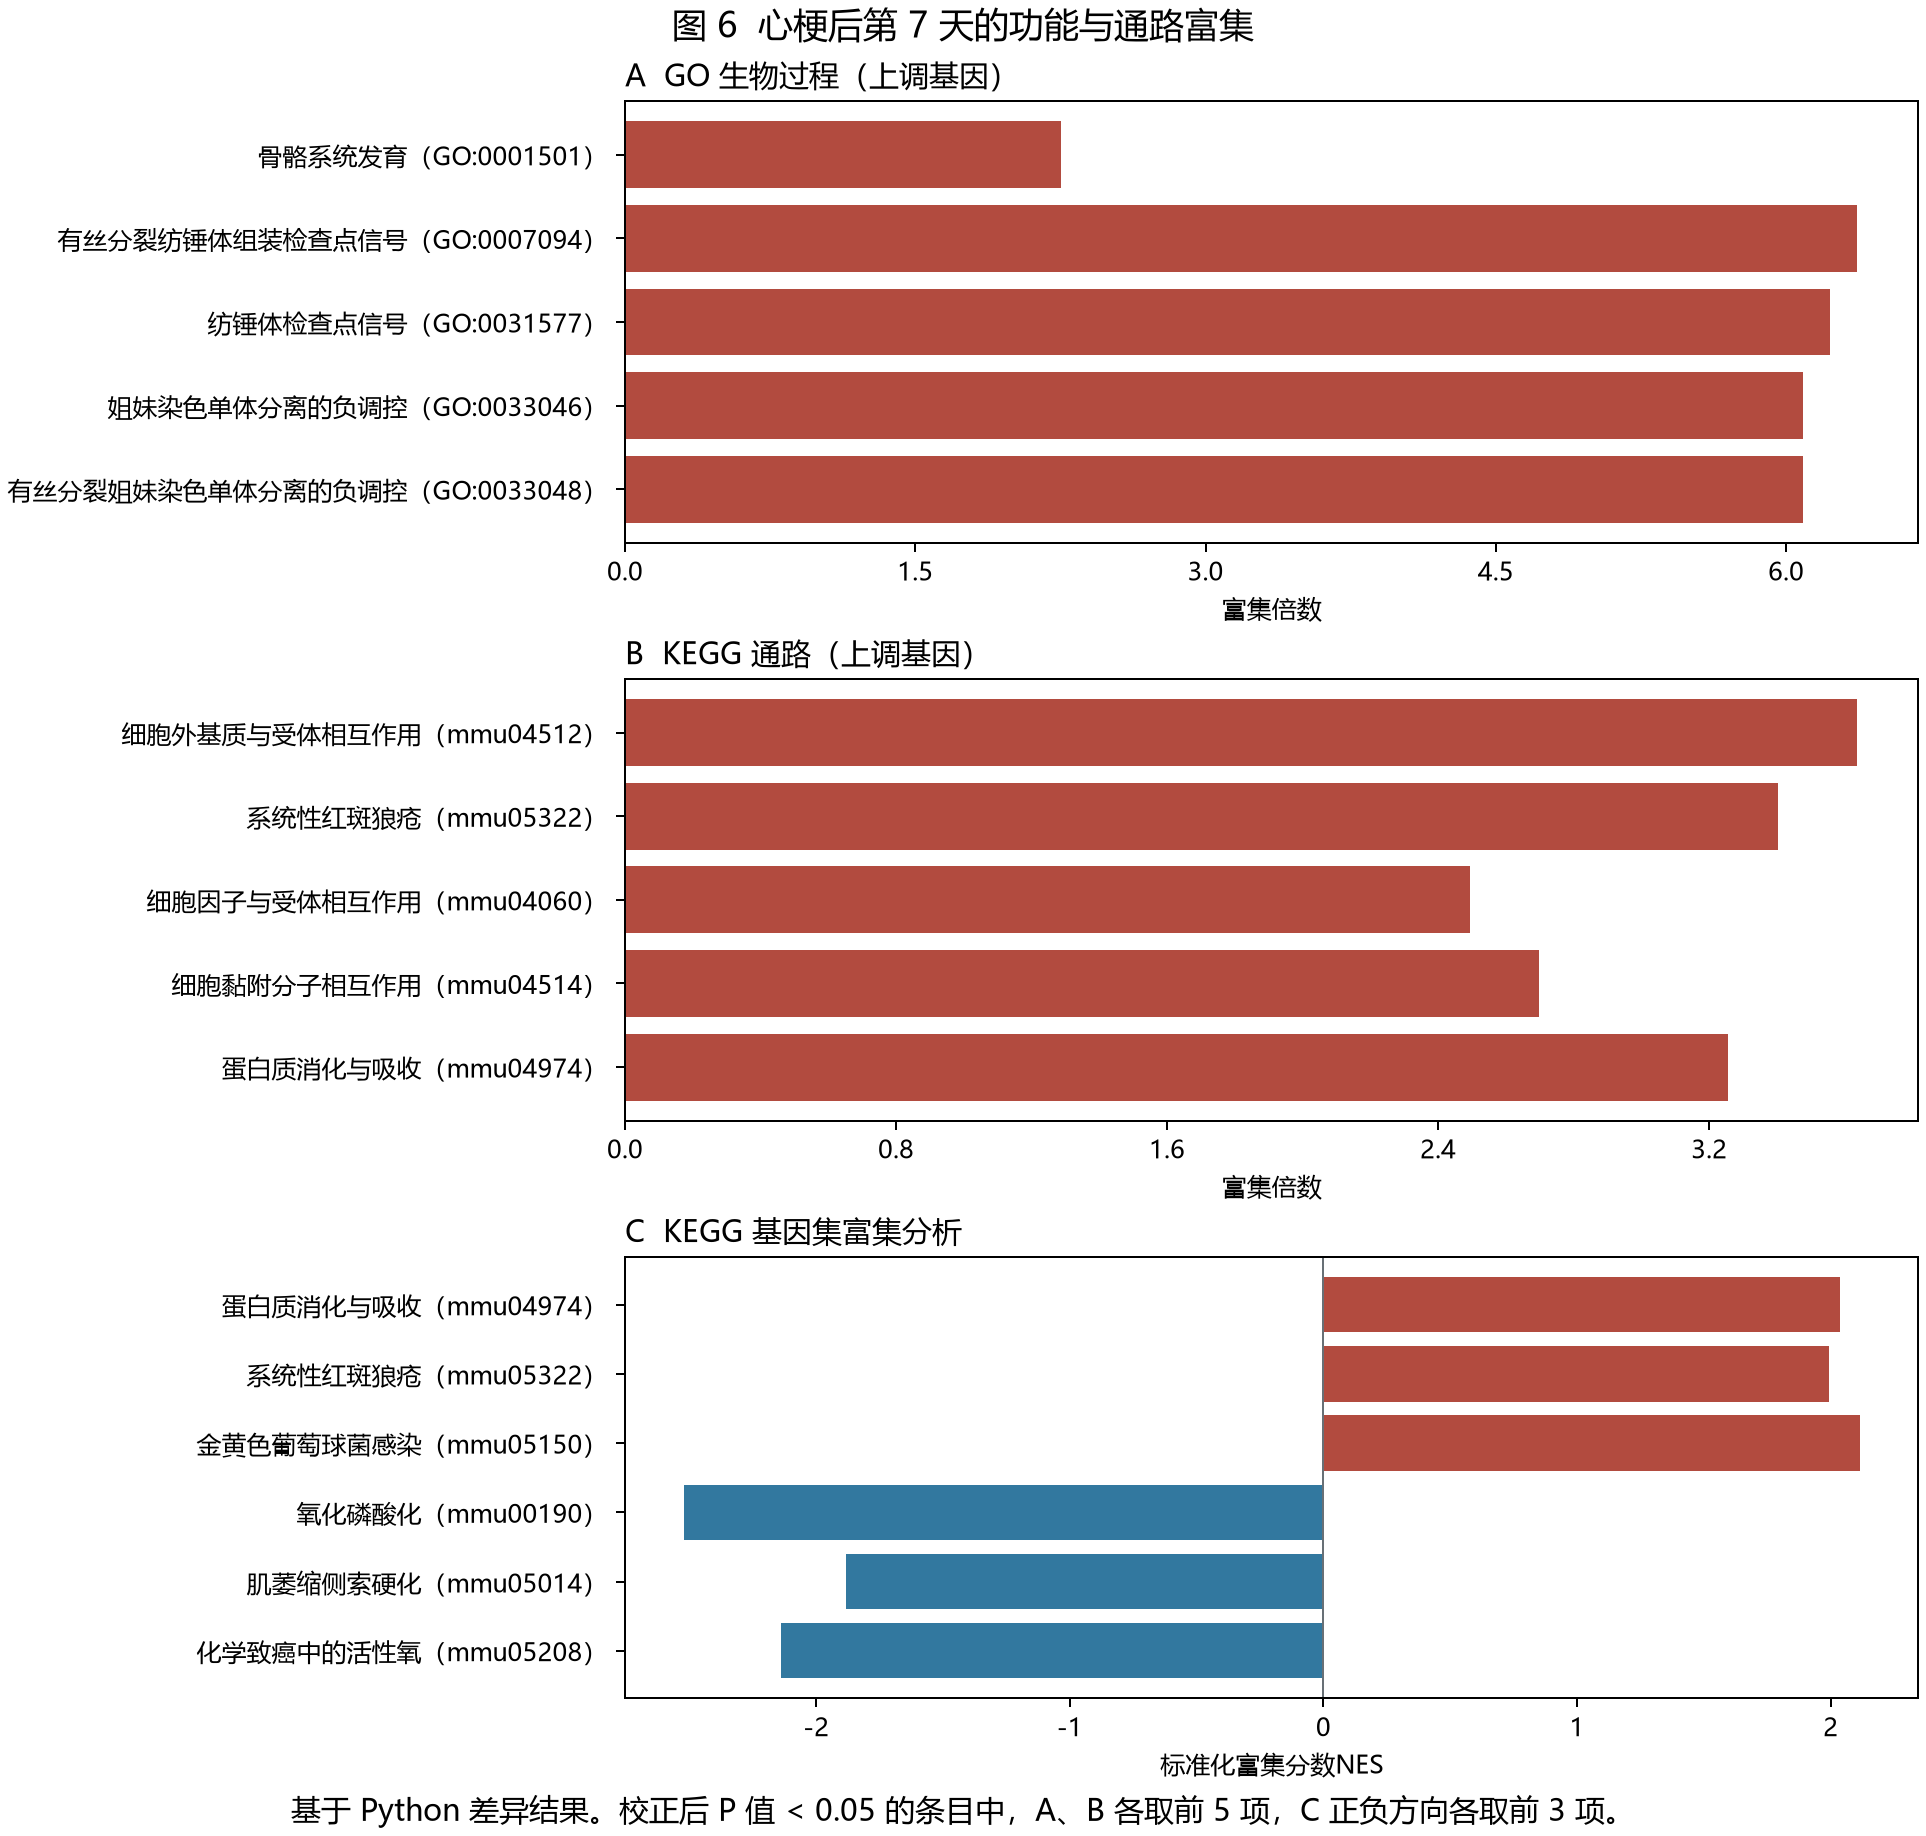

In [19]:
figures = [
    ('04_timecourse_heatmap.png', '图 4  总体时间效应排名前 25 个基因的表达模式'),
    ('05_timecourse_volcano.png', '图 5  心梗后各时间点相对未损伤对照的差异表达'),
    ('06_enrichment_D7.png', '图 6  心梗后第 7 天的功能与通路富集'),
]

for name, caption in figures:
    print(caption)
    display(Image(filename=str(OUT / 'figures' / name), width=860))

## 7 阶段结论与下一步

- 24 个提交文库中，主分析纳入 22 个，19,312 个基因通过低表达过滤并进入全时段模型；
  总体 LRT 找出在六个时间组之间存在表达差异的基因，Wald 表给出每个时间点相对 D0 的方向与幅度。
- D7 上调基因富集了细胞外基质组织与基质–受体相互作用，后者在 GSEA 中也偏向上调端。
  两类证据（ORA 的命中比例、GSEA 的排序偏向）回答的问题不同，需要一起看。
- 排除 D28r4 后，D28 对 D0 的入选名单变化明显大于总体时间效应，说明**晚期候选**要同时对照
  `timecourse_d28_sensitivity.tsv.gz` 中的两套效应与校正后 P 值。

阶段 01 把时间差异表、通路结果与样本敏感性证据交给后续模块。继续阅读：

- [阶段 01 方案](../experiments/01_preprocessing_differential/protocol.md) — 样本纳入与统计口径。
- [阶段 01 结果解读](../experiments/01_preprocessing_differential/results.md) — 每个数字与每张图怎么读。
- [数学原理](../docs/math/01_preprocessing_differential.md) — 公式与真实算例。
- [实验总览](../experiments/README.md) — 阶段 02–04 的输入、交付物与状态。